# Part 4: Preprocessing Temporal Data

Dataset: AAPL stock price (Kaggle - https://www.kaggle.com/datasets/khoongweihao/aaplcsv)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pandas.tseries.holiday import USFederalHolidayCalendar
import yfinance as yf

## Load Dataset

In [ ]:
df = yf.download("AAPL", start="2019-01-01", end="2021-01-01")

df.reset_index(inplace=True)

print(df.shape)
print(df.dtypes)
df.head()

/tmp/ipykernel_4135/2718692525.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download("AAPL", start="2019-01-01", end="2021-01-01")
[*********************100%***********************]  1 of 1 completed

(505, 6)
Price   Ticker
Date              datetime64[ns]
Close   AAPL             float64
High    AAPL             float64
Low     AAPL             float64
Open    AAPL             float64
Volume  AAPL               int64
dtype: object


Price,Date,Close,High,Low,Open,Volume
Ticker,,AAPL,AAPL,AAPL,AAPL,AAPL
0,2019-01-02,37.469208,37.689868,36.593692,36.750289,148158800
1,2019-01-03,33.737003,34.574556,33.691922,34.161710,365248800
2,2019-01-04,35.177208,35.246017,34.118999,34.292203,234428400
3,2019-01-07,35.098896,35.312438,34.617244,35.281593,219111200
4,2019-01-08,35.767998,36.021875,35.238893,35.485649,164101200


## a) Parsing Date and Time

Parse the Date column into datetime, handle multiple formats, set as index, and extract components.

In [ ]:
# Fix datetime parsing error and remove deprecated arguments
import pandas as pd

# 1. Parse datetime with fixed arguments
df['Date'] = pd.to_datetime(df['Date'], format='mixed', dayfirst=True)

# 2. Example mixed-format handling
sample_dates = pd.Series(['2020-01-15', '15/06/2020', 'Jul 4 2020'])
parsed = pd.to_datetime(sample_dates, format='mixed', dayfirst=True)
print("Mixed format parsing:\n", parsed.values)

# 3. Set index and extract components
df.set_index('Date', inplace=True)
df.sort_index(inplace=True)

df['year']   = df.index.year
df['month']  = df.index.month
df['day']    = df.index.day
df['hour']   = df.index.hour
df['minute'] = df.index.minute

print("Index dtype:", df.index.dtype)
print(df[['year', 'month', 'day', 'hour', 'minute']].head())

Mixed format parsing:
 ['2020-01-15T00:00:00.000000000' '2020-06-15T00:00:00.000000000'
 '2020-07-04T00:00:00.000000000']
Index dtype: datetime64[ns]
Price       year month day hour minute
Ticker                                
Date                                  
2019-01-02  2019     1   2    0      0
2019-01-03  2019     1   3    0      0
2019-01-04  2019     1   4    0      0
2019-01-07  2019     1   7    0      0
2019-01-08  2019     1   8    0      0


## b) Handling Time Gaps

Identify missing timestamps, then compare forward fill, backward fill, and interpolation methods.

In [ ]:
# Reindex to a full daily range to expose gaps (stock data skips weekends/holidays)
full_range = pd.date_range(start=df.index.min(), end=df.index.max(), freq='D')
df_full = df[['Close']].reindex(full_range)

missing_count = df_full['Close'].isna().sum()
print(f"Missing timestamps after reindex: {missing_count} out of {len(df_full)}")

# Show a few gaps
print(df_full[df_full['Close'].isna()].head(10))

Missing timestamps after reindex: Ticker
AAPL    225
dtype: int64 out of 730
Price      Close
Ticker      AAPL
2019-01-02   NaN
2019-01-03   NaN
2019-01-04   NaN
2019-01-05   NaN
2019-01-06   NaN
2019-01-07   NaN
2019-01-08   NaN
2019-01-09   NaN
2019-01-10   NaN
2019-01-11   NaN


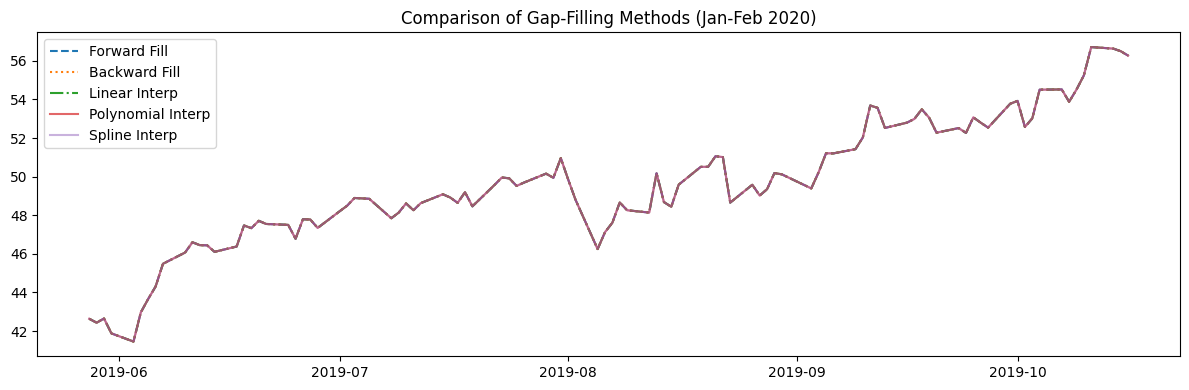


Comparison:
- Forward/backward fill: flat steps, no smooth transition, simple but introduces bias.
- Linear interpolation: straight line between known points, smooth but ignores curvature.
- Polynomial/spline: follows the trend curve more naturally; spline is smoother than polynomial.
For stock data with short gaps (weekends), linear or forward-fill are standard choices.



In [ ]:
# Forward fill
df_ffill = df_full.copy()
df_ffill['Close'] = df_ffill['Close'].ffill()

# Backward fill
df_bfill = df_full.copy()
df_bfill['Close'] = df_bfill['Close'].bfill()

# Linear interpolation
df_linear = df_full.copy()
df_linear['Close'] = df_linear['Close'].interpolate(method='linear')

# Polynomial interpolation (degree 2)
df_poly = df_full.copy()
df_poly['Close'] = df_poly['Close'].interpolate(method='polynomial', order=2)

# Spline interpolation
df_spline = df_full.copy()
df_spline['Close'] = df_spline['Close'].interpolate(method='spline', order=3)

# Visualize on a short window that contains gaps
gap_region = df.index[100:200]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df_ffill.loc[gap_region], label='Forward Fill', linestyle='--')
ax.plot(df_bfill.loc[gap_region], label='Backward Fill', linestyle=':')
ax.plot(df_linear.loc[gap_region], label='Linear Interp', linestyle='-.')
ax.plot(df_poly.loc[gap_region], label='Polynomial Interp', linestyle='-', alpha=0.7)
ax.plot(df_spline.loc[gap_region], label='Spline Interp', linestyle='-', alpha=0.5)
ax.set_title('Comparison of Gap-Filling Methods (Jan-Feb 2020)')
ax.legend()
plt.tight_layout()
plt.show()

print("""
Comparison:
- Forward/backward fill: flat steps, no smooth transition, simple but introduces bias.
- Linear interpolation: straight line between known points, smooth but ignores curvature.
- Polynomial/spline: follows the trend curve more naturally; spline is smoother than polynomial.
For stock data with short gaps (weekends), linear or forward-fill are standard choices.
""")

## c) Extracting Time-Based Features

Day of week, season, holiday/weekend indicators, sine/cosine cyclical encoding, and time-elapsed feature.

In [ ]:
# Work on original trading-day dataframe
df['day_of_week'] = df.index.dayofweek          # 0=Mon, 6=Sun
df['day_name']   = df.index.day_name()

# Season (Northern Hemisphere)
def get_season(month):
    if month in [12, 1, 2]: return 'Winter'
    if month in [3, 4, 5]:  return 'Spring'
    if month in [6, 7, 8]:  return 'Summer'
    return 'Fall'

df['season'] = df['month'].apply(get_season)

# Weekend indicator (stock market never trades on weekends, but useful for completeness)
df['is_weekend'] = df.index.dayofweek >= 5

# US Federal Holiday indicator
cal = USFederalHolidayCalendar()
holidays = cal.holidays(start=df.index.min(), end=df.index.max())
df['is_holiday'] = df.index.isin(holidays)

print(df[['day_of_week','day_name','season','is_weekend','is_holiday']].head(10))

Price      day_of_week   day_name  season is_weekend is_holiday
Ticker                                                         
Date                                                           
2019-01-02           2  Wednesday  Winter      False      False
2019-01-03           3   Thursday  Winter      False      False
2019-01-04           4     Friday  Winter      False      False
2019-01-07           0     Monday  Winter      False      False
2019-01-08           1    Tuesday  Winter      False      False
2019-01-09           2  Wednesday  Winter      False      False
2019-01-10           3   Thursday  Winter      False      False
2019-01-11           4     Friday  Winter      False      False
2019-01-14           0     Monday  Winter      False      False
2019-01-15           1    Tuesday  Winter      False      False


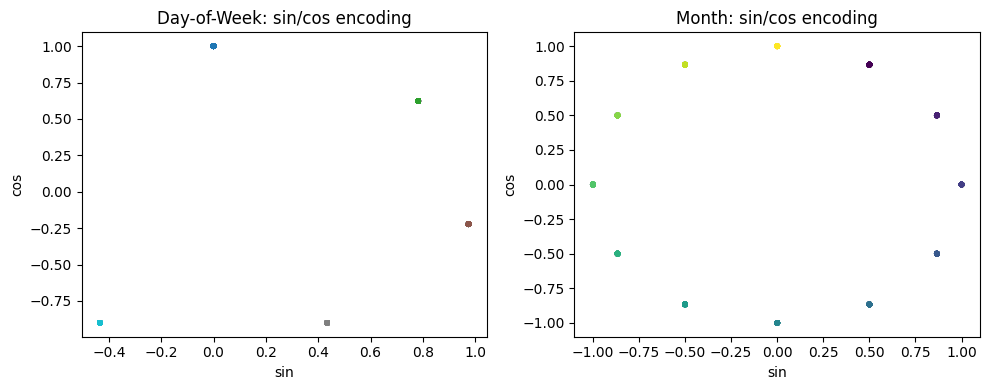

Price      day_of_week   dow_sin   dow_cos month month_sin month_cos
Ticker                                                              
Date                                                                
2019-01-02           2  0.974928 -0.222521     1       0.5  0.866025
2019-01-03           3  0.433884 -0.900969     1       0.5  0.866025
2019-01-04           4 -0.433884 -0.900969     1       0.5  0.866025
2019-01-07           0  0.000000  1.000000     1       0.5  0.866025
2019-01-08           1  0.781831  0.623490     1       0.5  0.866025


In [ ]:
# Sine/cosine encoding for cyclical features
# Day of week (period 7)
df['dow_sin'] = np.sin(2 * np.pi * df['day_of_week'] / 7)
df['dow_cos'] = np.cos(2 * np.pi * df['day_of_week'] / 7)

# Month (period 12)
df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)
df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(df['dow_sin'], df['dow_cos'], c=df['day_of_week'], cmap='tab10', s=10)
axes[0].set_title('Day-of-Week: sin/cos encoding')
axes[0].set_xlabel('sin'); axes[0].set_ylabel('cos')
axes[1].scatter(df['month_sin'], df['month_cos'], c=df['month'], cmap='viridis', s=10)
axes[1].set_title('Month: sin/cos encoding')
axes[1].set_xlabel('sin'); axes[1].set_ylabel('cos')
plt.tight_layout()
plt.show()

print(df[['day_of_week','dow_sin','dow_cos','month','month_sin','month_cos']].head())

In [ ]:
# Time elapsed since a specific event
# Event: COVID crash bottom ~2020-03-23
event_date = pd.Timestamp('2020-03-23')
df['days_since_covid_bottom'] = (df.index - event_date).days

print(df[['days_since_covid_bottom']].describe())
df[['Close','days_since_covid_bottom']].head(10)

Price  days_since_covid_bottom
Ticker                        
count               505.000000
mean                -81.184158
std                 211.205975
min                -446.000000
25%                -264.000000
50%                 -81.000000
75%                 101.000000
max                 283.000000


Price,Close,days_since_covid_bottom
Ticker,AAPL,
Date,,
2019-01-02,37.469208,-446
2019-01-03,33.737003,-445
2019-01-04,35.177208,-444
2019-01-07,35.098896,-441
2019-01-08,35.767998,-440
2019-01-09,36.375401,-439
2019-01-10,36.491650,-438
2019-01-11,36.133389,-437


## d) Resampling Time Series Data

Upsampling and downsampling with different aggregation functions, then comparing frequencies.

In [ ]:
# Downsampling: weekly and monthly with multiple aggregations
weekly_mean  = df['Close'].resample('W').mean()
weekly_max   = df['Close'].resample('W').max()
weekly_min   = df['Close'].resample('W').min()
weekly_sum   = df['Close'].resample('W').sum()

monthly_mean = df['Close'].resample('ME').mean()
quarterly_mean = df['Close'].resample('QE').mean()

print("Weekly (mean) sample:\n", weekly_mean.head())
print("\nMonthly (mean) sample:\n", monthly_mean.head())
print("\nQuarterly (mean) sample:\n", quarterly_mean.head())

Weekly (mean) sample:
 Ticker           AAPL
Date                 
2019-01-06  35.461140
2019-01-13  35.973466
2019-01-20  36.571863
2019-01-27  36.638768
2019-02-03  38.398818

Monthly (mean) sample:
 Ticker           AAPL
Date                 
2019-01-31  36.578549
2019-02-28  40.874205
2019-03-31  43.676090
2019-04-30  47.779920
2019-05-31  45.692748

Quarterly (mean) sample:
 Ticker           AAPL
Date                 
2019-03-31  40.359956
2019-06-30  46.536366
2019-09-30  50.130985
2019-12-31  61.900453
2020-03-31  70.940018


In [ ]:
# Upsampling: daily -> hourly with interpolation
df_up = df[['Close']].resample('h').interpolate(method='linear')
print("Shape before upsampling:", df[['Close']].resample('D').mean().shape)
print("Shape after upsampling to hourly:", df_up.shape)
df_up.head(10)

Shape before upsampling: (730, 1)
Shape after upsampling to hourly: (17497, 1)


Price,Close
Ticker,AAPL
Date,
2019-01-02 00:00:00,37.469208
2019-01-02 01:00:00,37.313699
2019-01-02 02:00:00,37.158191
2019-01-02 03:00:00,37.002682
2019-01-02 04:00:00,36.847174
2019-01-02 05:00:00,36.691665
2019-01-02 06:00:00,36.536157
2019-01-02 07:00:00,36.380648


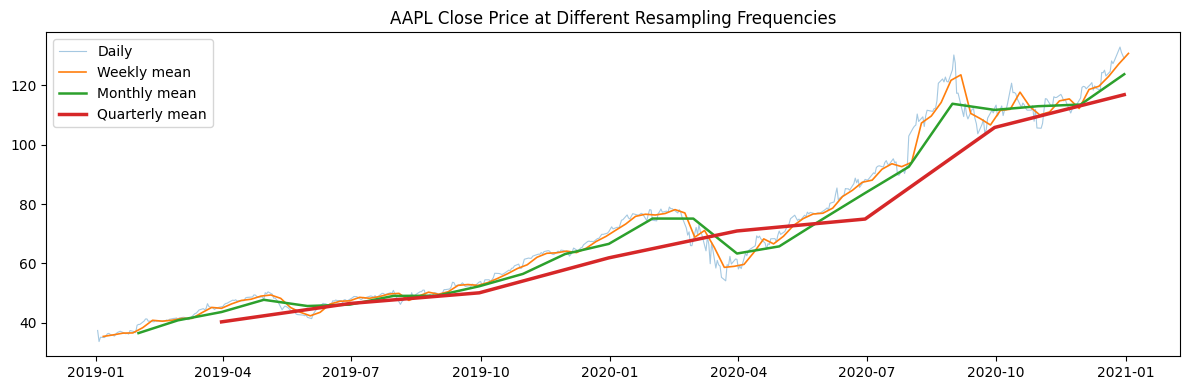


Observations:
- Higher frequency (daily) retains all volatility and short-term noise.
- Weekly/monthly smooths out noise and highlights the overall trend.
- Quarterly loses granularity but is useful for macro-level analysis.
- max/min aggregations preserve peaks/troughs; mean/sum provide central tendency.



In [ ]:
# Compare resampling frequencies
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df['Close'],       label='Daily',     alpha=0.4, linewidth=0.8)
ax.plot(weekly_mean,       label='Weekly mean',   linewidth=1.2)
ax.plot(monthly_mean,      label='Monthly mean',  linewidth=1.8)
ax.plot(quarterly_mean,    label='Quarterly mean',linewidth=2.5)
ax.set_title('AAPL Close Price at Different Resampling Frequencies')
ax.legend()
plt.tight_layout()
plt.show()

print("""
Observations:
- Higher frequency (daily) retains all volatility and short-term noise.
- Weekly/monthly smooths out noise and highlights the overall trend.
- Quarterly loses granularity but is useful for macro-level analysis.
- max/min aggregations preserve peaks/troughs; mean/sum provide central tendency.
""")

## e) Lag Features

Create lag features, rolling statistics, difference features, and analyze autocorrelation to choose lags.

In [ ]:
# Lag features: t-1, t-2, t-5 (1 week back)
for lag in [1, 2, 5]:
    df[f'Close_lag{lag}'] = df['Close'].shift(lag)

# Rolling window statistics
df['rolling_mean_7']  = df['Close'].rolling(window=7).mean()
df['rolling_std_7']   = df['Close'].rolling(window=7).std()
df['rolling_mean_30'] = df['Close'].rolling(window=30).mean()

# Difference features
df['diff_1']  = df['Close'].diff(1)   # daily change
df['diff_5']  = df['Close'].diff(5)   # weekly change
df['pct_change_1'] = df['Close'].pct_change(1)  # daily % return

df[['Close','Close_lag1','Close_lag2','Close_lag5',
    'rolling_mean_7','rolling_std_7','diff_1','pct_change_1']].dropna().head(10)

Price,Close,Close_lag1,Close_lag2,Close_lag5,rolling_mean_7,rolling_std_7,diff_1,pct_change_1
Ticker,AAPL,,,,,,,
Date,,,,,,,,
2019-01-10,36.491650,36.375401,35.767998,33.737003,35.731052,1.204079,0.116249,0.003196
2019-01-11,36.133389,36.491650,36.375401,35.177208,35.540221,0.964763,-0.358261,-0.009818
2019-01-14,35.590057,36.133389,36.491650,35.098896,35.804943,0.554521,-0.543331,-0.015037
2019-01-15,36.318455,35.590057,36.133389,35.767998,35.967978,0.504734,0.728397,0.020466
2019-01-16,36.762154,36.318455,35.590057,36.375401,36.205586,0.410030,0.443699,0.012217
2019-01-17,36.980434,36.762154,36.318455,36.491650,36.378791,0.448638,0.218281,0.005938
2019-01-18,37.208214,36.980434,36.762154,36.133389,36.497765,0.547190,0.227779,0.006159
2019-01-22,36.373024,37.208214,36.980434,35.590057,36.480818,0.549244,-0.835190,-0.022446


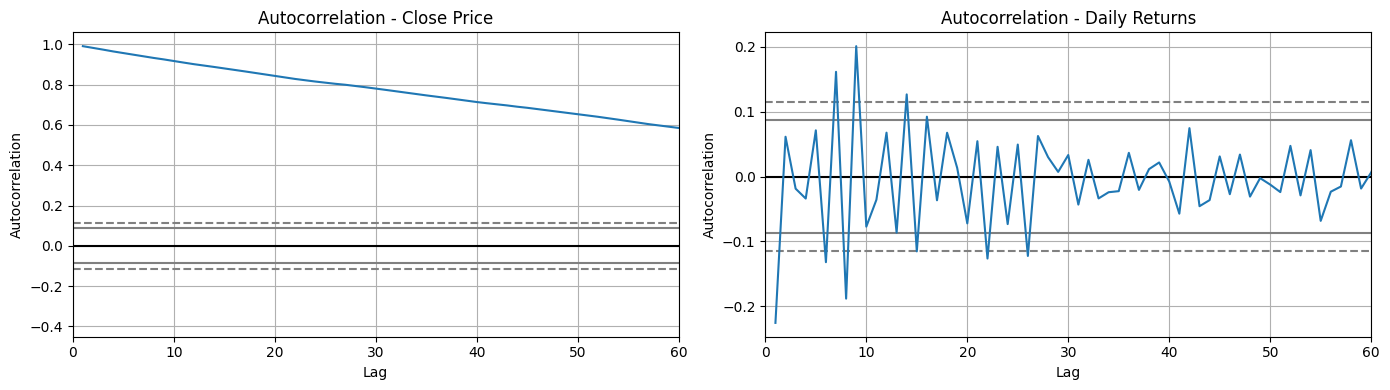


Autocorrelation analysis:
- Raw Close price shows high autocorrelation at all lags (non-stationary trend).
- Daily returns show near-zero autocorrelation, consistent with weak-form efficiency.
- Lag 1 and Lag 5 are common choices for stock data (next-day and weekly patterns).
- Rolling mean/std capture local trend and volatility, useful as features for ML models.



In [ ]:
from pandas.plotting import autocorrelation_plot

# ACF plot to identify significant lags
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Autocorrelation of Close price
autocorrelation_plot(df['Close'].dropna(), ax=axes[0])
axes[0].set_title('Autocorrelation - Close Price')
axes[0].set_xlim(0, 60)

# Autocorrelation of daily returns (more stationary)
autocorrelation_plot(df['pct_change_1'].dropna(), ax=axes[1])
axes[1].set_title('Autocorrelation - Daily Returns')
axes[1].set_xlim(0, 60)

plt.tight_layout()
plt.show()

print("""
Autocorrelation analysis:
- Raw Close price shows high autocorrelation at all lags (non-stationary trend).
- Daily returns show near-zero autocorrelation, consistent with weak-form efficiency.
- Lag 1 and Lag 5 are common choices for stock data (next-day and weekly patterns).
- Rolling mean/std capture local trend and volatility, useful as features for ML models.
""")

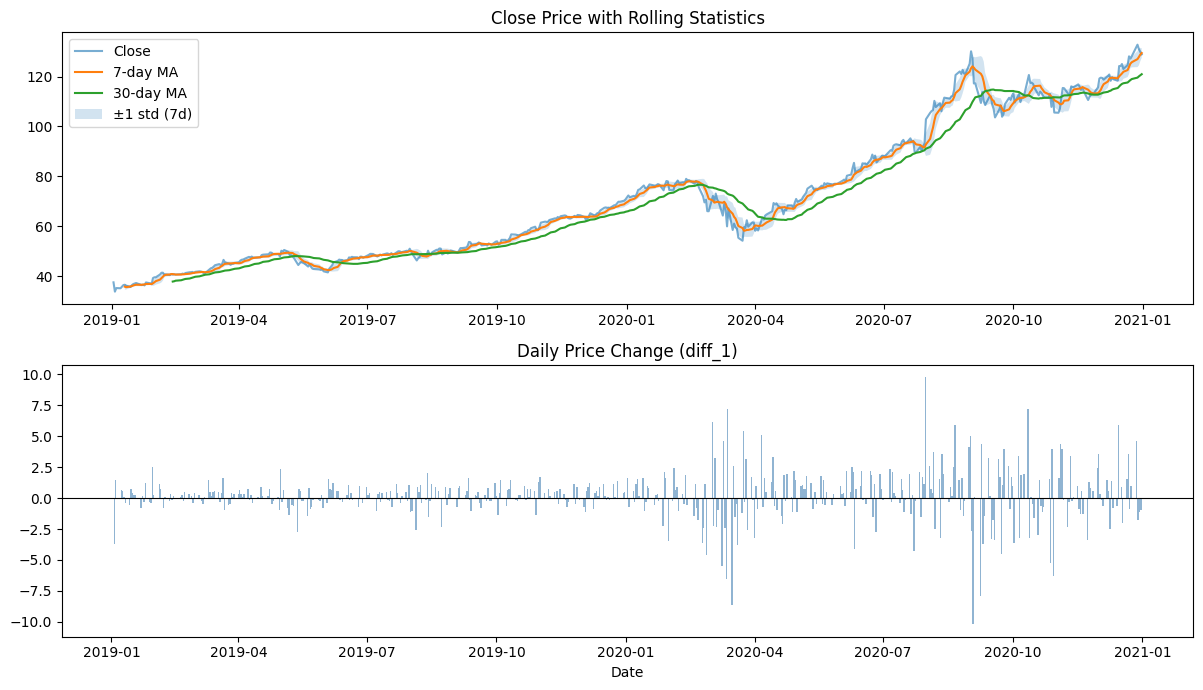

In [ ]:
# Visualize Close price with rolling stats and lag
fig, axes = plt.subplots(2, 1, figsize=(12, 7))

axes[0].plot(df['Close'], label='Close', alpha=0.6)
axes[0].plot(df['rolling_mean_7'], label='7-day MA')
axes[0].plot(df['rolling_mean_30'], label='30-day MA')
axes[0].fill_between(df.index,
    df['rolling_mean_7'] - df['rolling_std_7'],
    df['rolling_mean_7'] + df['rolling_std_7'],
    alpha=0.2, label='±1 std (7d)')
axes[0].set_title('Close Price with Rolling Statistics')
axes[0].legend()

axes[1].bar(df.index, df['diff_1'], color='steelblue', alpha=0.6, width=1)
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set_title('Daily Price Change (diff_1)')
axes[1].set_xlabel('Date')

plt.tight_layout()
plt.show()